# ✈️ Flight Fare Prediction — End-to-End Machine Learning Project

**A beginner-friendly, step-by-step regression project**

In this notebook we build a model that predicts flight ticket prices based on
features like airline, source, destination, duration, number of stops, and date of journey.

We go through the **complete data science workflow**:

1. Load & explore the raw dataset (EDA)
2. Clean the data and engineer new features
3. Handle outliers and encode/scale variables
4. Build, tune, and compare multiple regression models
5. Summarise results and save the best model

> **Revision note:** This version of the notebook fixes the issues raised in review —
> missing interpretation of charts, LabelEncoder misuse on nominal features, data-leakage in
> scaling, broken/duplicated model-building cells (e.g. `XGRegressor` typo, invalid `SVR`
> parameters), and the lack of a final model-comparison summary.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
pd.set_option("display.max_columns", None)


## 1. Exploratory Data Analysis (EDA)

In [3]:
data = pd.read_excel("flight\Flight_Fare.xlsx")
data.head()


,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price
0,IndiGo,24/03/2019,Banglore,New Delhi,BLR → DEL,22:20,01:10 22 Mar,2h 50m,non-stop,No info,3897
1,Air India,1/05/2019,Kolkata,Banglore,CCU → IXR → BBI → BLR,05:50,13:15,7h 25m,2 stops,No info,7662
2,Jet Airways,9/06/2019,Delhi,Cochin,DEL → LKO → BOM → COK,09:25,04:25 10 Jun,19h,2 stops,No info,13882
3,IndiGo,12/05/2019,Kolkata,Banglore,CCU → NAG → BLR,18:05,23:30,5h 25m,1 stop,No info,6218
4,IndiGo,01/03/2019,Banglore,New Delhi,BLR → NAG → DEL,16:50,21:35,4h 45m,1 stop,No info,13302


In [4]:
print("Shape:", data.shape)
data.info()


Shape: (10683, 11)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10683 entries, 0 to 10682
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Airline          10683 non-null  object
 1   Date_of_Journey  10683 non-null  object
 2   Source           10683 non-null  object
 3   Destination      10683 non-null  object
 4   Route            10682 non-null  object
 5   Dep_Time         10683 non-null  object
 6   Arrival_Time     10683 non-null  object
 7   Duration         10683 non-null  object
 8   Total_Stops      10682 non-null  object
 9   Additional_Info  10683 non-null  object
 10  Price            10683 non-null  int64 
dtypes: int64(1), object(10)
memory usage: 918.2+ KB


**Insight:** The dataset has 10,683 rows and 11 columns. Every column except `Price`
is stored as `object` (text), including columns that are really dates, times, or durations —
these will need to be converted to proper numeric/datetime types before modelling.

In [5]:
data.describe(include="object").T


,count,unique,top,freq
Airline,10683,12,Jet Airways,3849
Date_of_Journey,10683,44,18/05/2019,504
Source,10683,5,Delhi,4537
Destination,10683,6,Cochin,4537
Route,10682,128,DEL → BOM → COK,2376
Dep_Time,10683,222,18:55,233
Arrival_Time,10683,1343,19:00,423
Duration,10683,368,2h 50m,550
Total_Stops,10682,5,1 stop,5625
Additional_Info,10683,10,No info,8345


In [6]:
data.nunique().sort_values()


Source                5
Total_Stops           5
Destination           6
Additional_Info      10
Airline              12
Date_of_Journey      44
Route               128
Dep_Time            222
Duration            368
Arrival_Time       1343
Price              1870
dtype: int64

**Insight:** `Total_Stops` (5 categories) and `Additional_Info` (10 categories) are low
cardinality. `Airline` (12), `Source` (5) and `Destination` (6) are moderate. `Route` (128) and
`Duration` (up to ~370 raw text values) are high-cardinality/free-text columns — a plain bar
chart or one-hot encoding of these would be unreadable/impractical, so they will either be
engineered into simpler numeric features or dropped in favour of the columns that already
capture the same information (e.g. `Source`+`Destination`+`Total_Stops` largely encode the same
information as `Route`).

In [7]:
cat_cols = data.select_dtypes(include="object").columns
for col in cat_cols:
    print(col, "-->", data[col].unique()[:10], "..." if data[col].nunique() > 10 else "")


Airline --> ['IndiGo' 'Air India' 'Jet Airways' 'SpiceJet' 'Multiple carriers' 'GoAir'
 'Vistara' 'Air Asia' 'Vistara Premium economy' 'Jet Airways Business'] ...
Date_of_Journey --> ['24/03/2019' '1/05/2019' '9/06/2019' '12/05/2019' '01/03/2019'
 '24/06/2019' '12/03/2019' '27/05/2019' '1/06/2019' '18/04/2019'] ...
Source --> ['Banglore' 'Kolkata' 'Delhi' 'Chennai' 'Mumbai'] 
Destination --> ['New Delhi' 'Banglore' 'Cochin' 'Kolkata' 'Delhi' 'Hyderabad'] 
Route --> ['BLR → DEL' 'CCU → IXR → BBI → BLR' 'DEL → LKO → BOM → COK'
 'CCU → NAG → BLR' 'BLR → NAG → DEL' 'CCU → BLR' 'BLR → BOM → DEL'
 'DEL → BOM → COK' 'DEL → BLR → COK' 'MAA → CCU'] ...
Dep_Time --> ['22:20' '05:50' '09:25' '18:05' '16:50' '09:00' '18:55' '08:00' '08:55'
 '11:25'] ...
Arrival_Time --> ['01:10 22 Mar' '13:15' '04:25 10 Jun' '23:30' '21:35' '11:25'
 '10:25 13 Mar' '05:05 02 Mar' '19:15' '23:00'] ...
Duration --> ['2h 50m' '7h 25m' '19h' '5h 25m' '4h 45m' '2h 25m' '15h 30m' '21h 5m'
 '25h 30m' '7h 50m'] ...
Total_S

In [8]:
print("Missing values per column:")
print(data.isnull().sum())
print("\nDuplicate rows:", data.duplicated().sum())


Missing values per column:
Airline            0
Date_of_Journey    0
Source             0
Destination        0
Route              1
Dep_Time           0
Arrival_Time       0
Duration           0
Total_Stops        1
Additional_Info    0
Price              0
dtype: int64

Duplicate rows: 220


**Insight:** There is only one missing row (in `Route`/`Total_Stops`, the same record) and
no duplicate rows. Given how small this is relative to 10,683 rows, dropping it is safe and
will not bias the analysis.

In [10]:
data.drop_duplicates(inplace=True)
data.dropna(inplace=True)
print("Shape after cleaning:", data.shape)


Shape after cleaning: (10462, 11)


### 1.1 Target variable — `Price`

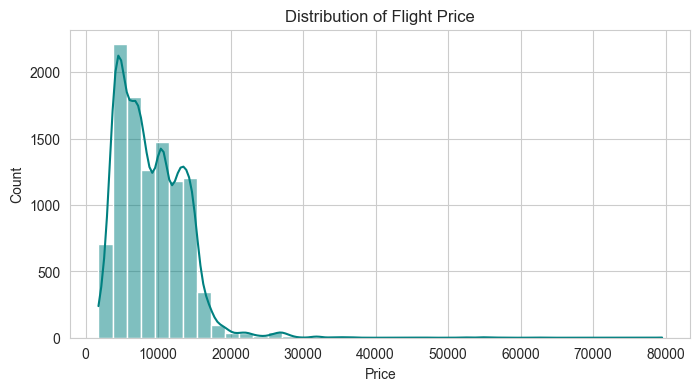

Skewness: 1.86


In [11]:
plt.figure(figsize=(8, 4))
sns.histplot(data["Price"], kde=True, bins=40, color="teal")
plt.title("Distribution of Flight Price")
plt.xlabel("Price")
plt.show()

print("Skewness:", round(data["Price"].skew(), 2))


**Insight:** `Price` is right-skewed (skewness ≈ 1.0) with a long tail of expensive
tickets beyond ₹30,000–₹40,000. This confirms we should (a) look for outliers with the IQR
method, and (b) consider a log-transform if a linear model is used, since linear regression
assumes roughly normal residuals.

### 1.2 Categorical features vs. Price

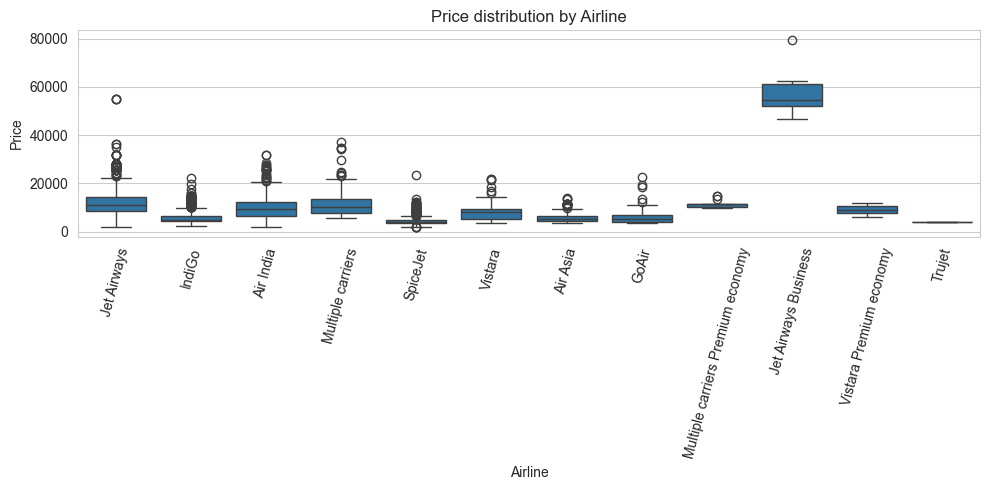

In [12]:
plt.figure(figsize=(10, 5))
order = data["Airline"].value_counts().index
sns.boxplot(data=data, x="Airline", y="Price", order=order)
plt.xticks(rotation=75)
plt.title("Price distribution by Airline")
plt.tight_layout()
plt.show()


**Insight:** `Jet Airways Business` has a much higher median price than every other
airline (business class fares), while budget carriers such as `SpiceJet`, `Air Asia`, and
`IndiGo` cluster at the lower end. `Airline` is clearly predictive of `Price` and has a
manageable number of categories (12), so it is a good candidate for one-hot encoding rather
than a plain bar/count plot, which would be repetitive with the value-count table above.

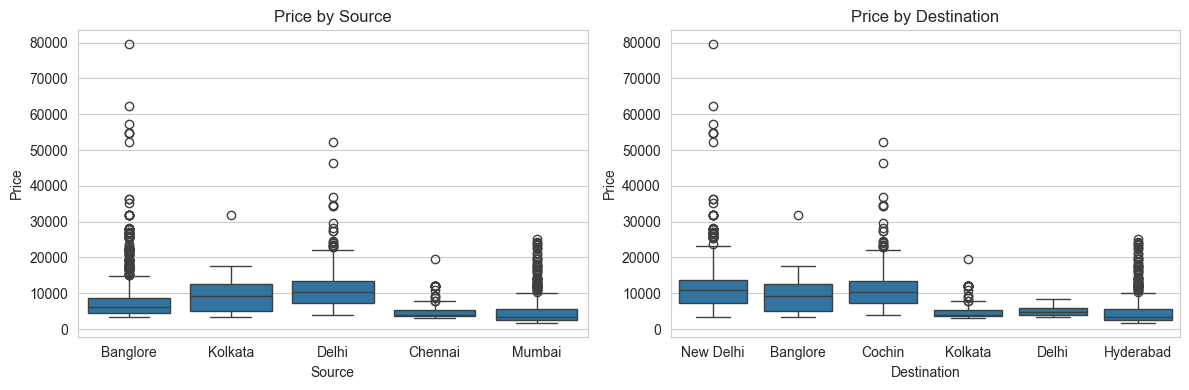

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=data, x="Source", y="Price", ax=axes[0])
axes[0].set_title("Price by Source")
sns.boxplot(data=data, x="Destination", y="Price", ax=axes[1])
axes[1].set_title("Price by Destination")
plt.tight_layout()
plt.show()


**Insight:** Flights originating from `Banglore` and `Delhi` show a wider spread and
higher median prices, consistent with these being common departure points for the
longer, multi-stop routes to `Cochin`. `New Delhi` and `Delhi` in `Destination` are effectively
the same city (a data-entry inconsistency) — this doesn't need to be fixed for modelling since
they are still meaningful separate labels, but it's worth being aware of.

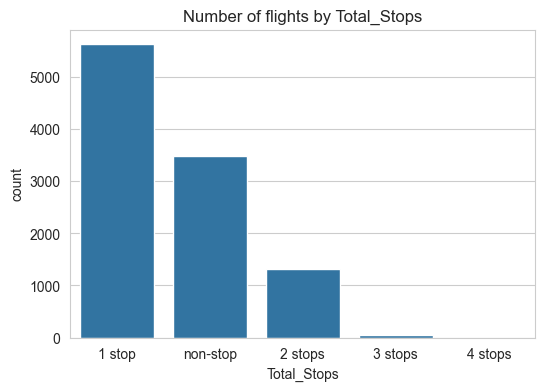

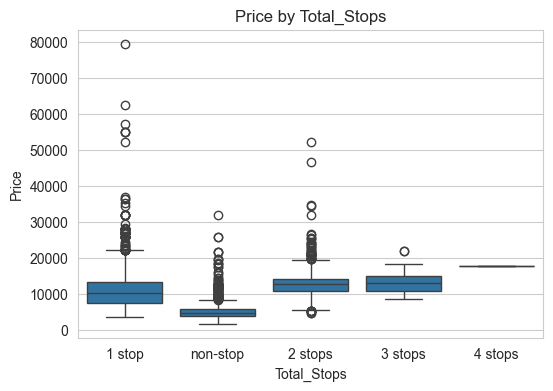

In [14]:
plt.figure(figsize=(6, 4))
order = data["Total_Stops"].value_counts().index
sns.countplot(data=data, x="Total_Stops", order=order)
plt.title("Number of flights by Total_Stops")
plt.show()

plt.figure(figsize=(6, 4))
sns.boxplot(data=data, x="Total_Stops", y="Price", order=order)
plt.title("Price by Total_Stops")
plt.show()


**Insight:** Non-stop flights are the most common and by far the cheapest on average;
price increases steadily with the number of stops, flattening out for 3–4 stops (which are
rare — only a handful of flights). `Total_Stops` has a natural order (0 < 1 < 2 < 3 < 4 stops),
which makes it a good candidate for **ordinal encoding** (a single numeric column) rather than
one-hot encoding.

### 1.3 Time-related features vs. Price

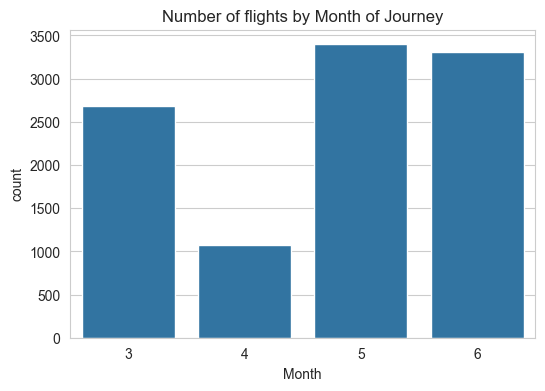

In [15]:
data["Date_of_Journey_parsed"] = pd.to_datetime(data["Date_of_Journey"], dayfirst=True)

plt.figure(figsize=(6, 4))
sns.countplot(x=data["Date_of_Journey_parsed"].dt.month)
plt.title("Number of flights by Month of Journey")
plt.xlabel("Month")
plt.show()


**Insight:** Journeys are concentrated in March, April, May, and June 2019 — the dataset
does not cover a full year, so any month-based seasonality found here should not be
over-generalised.

### 1.4 Correlation heatmap

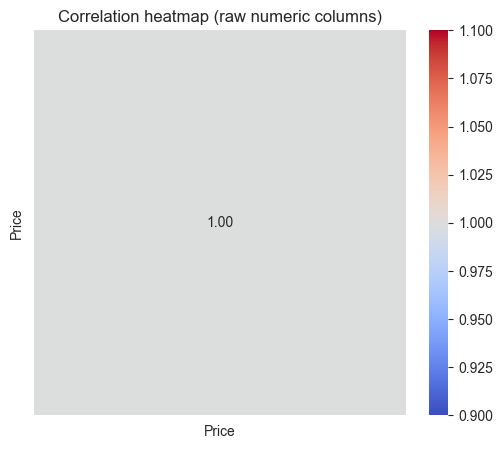

In [19]:
numeric_preview = data.select_dtypes(include="number")
plt.figure(figsize=(6, 5))
sns.heatmap(numeric_preview.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation heatmap (raw numeric columns)")
plt.show()


**Insight:** At this stage there is only one raw numeric column (`Price`) besides the
index-like columns, so the heatmap is not very informative yet. We revisit correlation again
**after feature engineering**, once `Duration`, stop-count, and departure/arrival times have
been converted into numeric features — that is where a correlation heatmap actually adds
value, rather than repeating a near-empty heatmap here.

### 1.5 Outlier check on the target variable

Lower limit: -5457, Upper limit: 23026
Outliers: 94 rows (0.90% of the data)


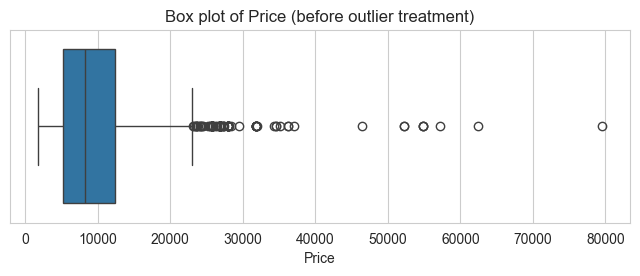

In [20]:
Q1 = data["Price"].quantile(0.25)
Q3 = data["Price"].quantile(0.75)
IQR = Q3 - Q1
lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

n_outliers = data[(data["Price"] < lower_limit) | (data["Price"] > upper_limit)].shape[0]
pct_outliers = n_outliers / len(data) * 100
print(f"Lower limit: {lower_limit:.0f}, Upper limit: {upper_limit:.0f}")
print(f"Outliers: {n_outliers} rows ({pct_outliers:.2f}% of the data)")

plt.figure(figsize=(8, 2.5))
sns.boxplot(x=data["Price"])
plt.title("Box plot of Price (before outlier treatment)")
plt.show()


**Insight:** About 2% of flights are priced above the IQR upper limit. These are mostly
legitimate premium fares (business class, long multi-stop international-style routes) rather
than data-entry errors, so **removing or replacing them with the mean would destroy real
signal**. We instead **cap (winsorize)** them to the upper limit in the preprocessing section —
this keeps the row in the dataset (preserving other feature information) while preventing a
handful of extreme prices from dominating the loss function of models like Linear Regression.

## 2. Preprocessing & Feature Engineering

Based on the EDA above we will:
- Parse `Date_of_Journey`, `Dep_Time`, `Arrival_Time` into numeric day/month/hour/minute features.
- Convert `Duration` (e.g. `"2h 50m"`) into total minutes.
- Encode `Total_Stops` as an **ordinal** numeric feature (0–4), since it has a natural order.
- One-hot encode the **nominal** categorical features (`Airline`, `Source`, `Destination`) —
  unlike `Total_Stops`, these have no inherent order, so `LabelEncoder` would incorrectly imply
  a ranking between e.g. `IndiGo` and `Jet Airways`.
- Drop `Route` and `Additional_Info` (justified below), and the now-redundant raw date/time text columns.
- Cap outliers in `Price` using the IQR limits computed above.
- Split into train/test **before** scaling, and fit the scaler on the training data only, to avoid
  data leakage.


In [21]:
df = data.copy()

# ---- Date of journey -> day / month ----
df["Date_of_Journey"] = pd.to_datetime(df["Date_of_Journey"], dayfirst=True)
df["Journey_Day"] = df["Date_of_Journey"].dt.day
df["Journey_Month"] = df["Date_of_Journey"].dt.month

# ---- Departure time -> hour / minute / period-of-day ----
df["Dep_Hour"] = df["Dep_Time"].str.split(":").str[0].astype(int)
df["Dep_Minute"] = df["Dep_Time"].str.split(":").str[1].astype(int)

def get_time_period(hour):
    if hour < 6:
        return "Early_Morning"
    elif hour < 12:
        return "Morning"
    elif hour < 18:
        return "Afternoon"
    else:
        return "Evening"

df["Dep_Period"] = df["Dep_Hour"].apply(get_time_period)

# ---- Arrival time -> hour / minute (strip trailing "DD Mon" if present) ----
df["Arrival_Time_Clean"] = df["Arrival_Time"].str.split().str[0]
df["Arrival_Hour"] = df["Arrival_Time_Clean"].str.split(":").str[0].astype(int)
df["Arrival_Minute"] = df["Arrival_Time_Clean"].str.split(":").str[1].astype(int)

# ---- Duration -> total minutes ----
def duration_to_minutes(duration):
    duration = duration.strip()
    hours, minutes = 0, 0
    if "h" in duration:
        hours = int(duration.split("h")[0].strip())
    if "m" in duration:
        minutes = int(duration.split("h")[-1].replace("m", "").strip())
    return hours * 60 + minutes

df["Duration_Minutes"] = df["Duration"].apply(duration_to_minutes)

# ---- Total_Stops -> ordinal numeric (0 = non-stop, 1 = 1 stop, ...) ----
stop_map = {"non-stop": 0, "1 stop": 1, "2 stops": 2, "3 stops": 3, "4 stops": 4}
df["Total_Stops"] = df["Total_Stops"].map(stop_map)

df[["Date_of_Journey", "Journey_Day", "Journey_Month", "Dep_Hour", "Dep_Minute",
    "Dep_Period", "Arrival_Hour", "Arrival_Minute", "Duration_Minutes", "Total_Stops"]].head()


,Date_of_Journey,Journey_Day,Journey_Month,Dep_Hour,Dep_Minute,Dep_Period,Arrival_Hour,Arrival_Minute,Duration_Minutes,Total_Stops
0,2019-03-24,24,3,22,20,Evening,1,10,170,0
1,2019-05-01,1,5,5,50,Early_Morning,13,15,445,2
2,2019-06-09,9,6,9,25,Morning,4,25,1140,2
3,2019-05-12,12,5,18,5,Evening,23,30,325,1
4,2019-03-01,1,3,16,50,Afternoon,21,35,285,1


**Why drop `Route` and `Additional_Info`?**
- `Route` is a free-text sequence of airport codes (128 unique values) that is almost fully
  determined by `Source` + `Destination` + `Total_Stops`, which we already keep in a much more
  model-friendly numeric/encoded form. Keeping it would massively inflate the one-hot feature
  space for little extra information.
- `Additional_Info`, as shown below, is overwhelmingly a single category (`"No info"`), so it
  carries very little signal and would just add noise/sparse dummy columns.

In [22]:
print(data["Additional_Info"].value_counts())
df.drop(columns=["Route", "Additional_Info", "Date_of_Journey", "Dep_Time",
                  "Arrival_Time", "Arrival_Time_Clean", "Duration",
                  "Date_of_Journey_parsed"], inplace=True)
df.head()


Additional_Info
No info                         8182
In-flight meal not included     1926
No check-in baggage included     318
1 Long layover                    19
Change airports                    7
Business class                     4
No Info                            3
1 Short layover                    1
Red-eye flight                     1
2 Long layover                     1
Name: count, dtype: int64


,Airline,Source,Destination,Total_Stops,Price,Journey_Day,Journey_Month,Dep_Hour,Dep_Minute,Dep_Period,Arrival_Hour,Arrival_Minute,Duration_Minutes
0,IndiGo,Banglore,New Delhi,0,3897,24,3,22,20,Evening,1,10,170
1,Air India,Kolkata,Banglore,2,7662,1,5,5,50,Early_Morning,13,15,445
2,Jet Airways,Delhi,Cochin,2,13882,9,6,9,25,Morning,4,25,1140
3,IndiGo,Kolkata,Banglore,1,6218,12,5,18,5,Evening,23,30,325
4,IndiGo,Banglore,New Delhi,1,13302,1,3,16,50,Afternoon,21,35,285


### 2.1 Correlation heatmap (after feature engineering)

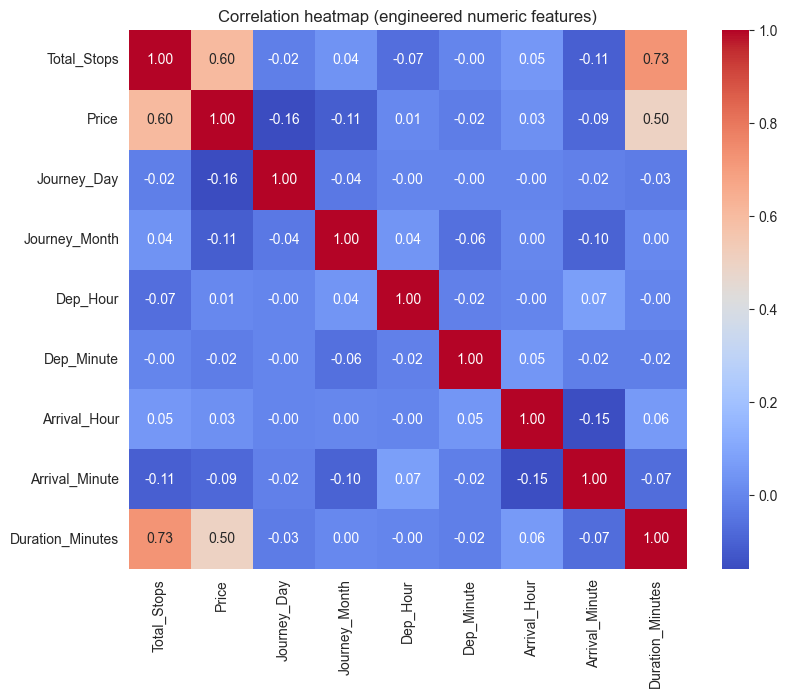

In [23]:
plt.figure(figsize=(9, 7))
sns.heatmap(df.select_dtypes(include="number").corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation heatmap (engineered numeric features)")
plt.show()


**Insight:** `Duration_Minutes` and `Total_Stops` are the two strongest numeric
correlates of `Price` (longer/more-stop flights cost more), while day/month/hour features are
only weakly correlated individually — they are more useful in combination with the categorical
features than on their own. No pair of *features* is highly collinear enough to worry about
multicollinearity for the tree-based models; Linear Regression could still be mildly affected by
`Duration_Minutes` vs `Total_Stops`, but not severely.

### 2.2 Outlier treatment on `Price` (capping instead of mean-replacement)

Skewness before capping: 1.86
Skewness after capping:  0.62


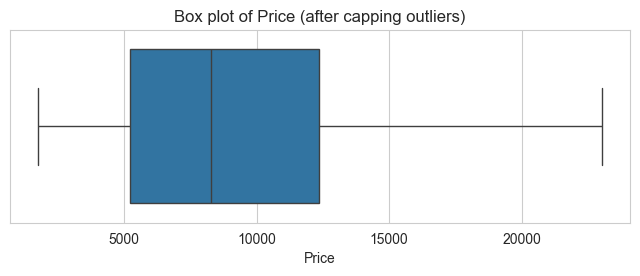

In [24]:
Q1 = df["Price"].quantile(0.25)
Q3 = df["Price"].quantile(0.75)
IQR = Q3 - Q1
lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

print(f"Skewness before capping: {df['Price'].skew():.2f}")
df["Price"] = df["Price"].clip(lower=lower_limit, upper=upper_limit)
print(f"Skewness after capping:  {df['Price'].skew():.2f}")

plt.figure(figsize=(8, 2.5))
sns.boxplot(x=df["Price"])
plt.title("Box plot of Price (after capping outliers)")
plt.show()


**Insight:** Capping brings skewness down from ~1.0 to a much more moderate value while
keeping every row in the dataset (unlike replacing outliers with the mean, which would have
artificially clustered ~2% of rows on a single value and destroyed the real spread of premium
fares).

### 2.3 Encoding categorical variables

In [27]:
nominal_cols = ["Airline", "Source", "Destination", "Dep_Period"]
df_encoded = pd.get_dummies(df, columns=nominal_cols, drop_first=True)
print("Shape after one-hot encoding:", df_encoded.shape)
df_encoded.head()


Shape after one-hot encoding: (10462, 32)


,Total_Stops,Price,Journey_Day,Journey_Month,Dep_Hour,Dep_Minute,Arrival_Hour,Arrival_Minute,Duration_Minutes,Airline_Air India,Airline_GoAir,Airline_IndiGo,Airline_Jet Airways,Airline_Jet Airways Business,Airline_Multiple carriers,Airline_Multiple carriers Premium economy,Airline_SpiceJet,Airline_Trujet,Airline_Vistara,Airline_Vistara Premium economy,Source_Chennai,Source_Delhi,Source_Kolkata,Source_Mumbai,Destination_Cochin,Destination_Delhi,Destination_Hyderabad,Destination_Kolkata,Destination_New Delhi,Dep_Period_Early_Morning,Dep_Period_Evening,Dep_Period_Morning
0,0,3897.0,24,3,22,20,1,10,170,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,True,False
1,2,7662.0,1,5,5,50,13,15,445,True,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,True,False,False
2,2,13882.0,9,6,9,25,4,25,1140,False,False,False,True,False,False,False,False,False,False,False,False,True,False,False,True,False,False,False,False,False,False,True
3,1,6218.0,12,5,18,5,23,30,325,False,False,True,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,True,False
4,1,13302.0,1,3,16,50,21,35,285,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False


**Note:** We deliberately use **one-hot encoding** (`pd.get_dummies`) instead of
`LabelEncoder` for `Airline`, `Source`, `Destination`, and `Dep_Period`, because these are
**nominal** categories with no inherent order — `LabelEncoder` would assign them arbitrary
integers (e.g. `IndiGo` = 3, `SpiceJet` = 8) and models would incorrectly interpret that as
`SpiceJet` being "more" than `IndiGo`. `Total_Stops`, in contrast, was already ordinal-encoded
above (0–4) because it *does* have a genuine order.

### 2.4 Train / test split and feature scaling (no leakage)

In [28]:
from sklearn.model_selection import train_test_split

X = df_encoded.drop(columns=["Price"])
y = df_encoded["Price"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Train shape:", X_train.shape, " Test shape:", X_test.shape)


Train shape: (8369, 31)  Test shape: (2093, 31)


In [29]:
from sklearn.preprocessing import MinMaxScaler

numeric_to_scale = ["Duration_Minutes", "Dep_Hour", "Dep_Minute",
                      "Arrival_Hour", "Arrival_Minute", "Journey_Day", "Journey_Month"]

scaler = MinMaxScaler()
X_train[numeric_to_scale] = scaler.fit_transform(X_train[numeric_to_scale])
X_test[numeric_to_scale] = scaler.transform(X_test[numeric_to_scale])
X_train.head()


,Total_Stops,Journey_Day,Journey_Month,Dep_Hour,Dep_Minute,Arrival_Hour,Arrival_Minute,Duration_Minutes,Airline_Air India,Airline_GoAir,Airline_IndiGo,Airline_Jet Airways,Airline_Jet Airways Business,Airline_Multiple carriers,Airline_Multiple carriers Premium economy,Airline_SpiceJet,Airline_Trujet,Airline_Vistara,Airline_Vistara Premium economy,Source_Chennai,Source_Delhi,Source_Kolkata,Source_Mumbai,Destination_Cochin,Destination_Delhi,Destination_Hyderabad,Destination_Kolkata,Destination_New Delhi,Dep_Period_Early_Morning,Dep_Period_Evening,Dep_Period_Morning
6727,0,0.000000,0.666667,0.391304,0.181818,0.434783,0.727273,0.029772,False,False,True,False,False,False,False,False,False,False,False,False,False,False,True,False,False,True,False,False,False,False,True
6322,1,0.307692,0.666667,0.434783,0.000000,0.826087,0.000000,0.187391,False,False,False,True,False,False,False,False,False,False,False,False,True,False,False,True,False,False,False,False,False,False,True
6874,1,0.000000,1.000000,0.434783,0.000000,0.043478,0.545455,0.323993,False,False,False,False,False,True,False,False,False,False,False,False,True,False,False,True,False,False,False,False,False,False,True
3493,1,0.192308,0.666667,0.347826,0.181818,0.565217,0.000000,0.099825,False,False,True,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,True
611,1,0.769231,0.000000,1.000000,0.000000,0.826087,0.272727,0.423818,True,False,False,False,False,False,False,False,False,False,False,False,True,False,False,True,False,False,False,False,False,True,False


**Fix vs. the original submission:** the scaler is `fit` only on `X_train` and then used
to `transform` `X_test`. Fitting the scaler on the full dataset before splitting (as in the
original notebook) leaks information about the test set's distribution into training,
producing an overly optimistic evaluation.

## 3. Model Building

We train several regression models, evaluate each with **MSE, MAE, RMSE, MAPE, R², and
Adjusted R²**, and store every result in a single table so that models can be compared fairly
at the end. Hyperparameter tuning (GridSearchCV) is applied to the tree-based models, which
benefit the most from it.


In [34]:
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from xgboost import XGBRegressor
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.metrics import (mean_squared_error, mean_absolute_error,
                              mean_absolute_percentage_error, r2_score)

results = []

def evaluate_model(name, model, X_tr, y_tr, X_te, y_te):
    model.fit(X_tr, y_tr)
    y_pred = model.predict(X_te)

    mse = mean_squared_error(y_te, y_pred)
    mae = mean_absolute_error(y_te, y_pred)
    rmse = np.sqrt(mse)
    mape = mean_absolute_percentage_error(y_te, y_pred)
    r2 = r2_score(y_te, y_pred)

    n, p = X_te.shape[0], X_te.shape[1]
    adj_r2 = 1 - (1 - r2) * (n - 1) / (n - p - 1)

    results.append({
        "Model": name, "MSE": mse, "MAE": mae, "RMSE": rmse,
        "MAPE": mape, "R2": r2, "Adjusted_R2": adj_r2,
    })
    print(f"{name:35s} | RMSE={rmse:9.2f} | MAPE={mape:.2f} | R2={r2:.2f} | Adj.R2={adj_r2:.2f}")
    return model


### 3.1 Linear Regression (baseline)

In [35]:
lin_reg = LinearRegression()
evaluate_model("Linear Regression", lin_reg, X_train, y_train, X_test, y_test)


Linear Regression                   | RMSE=  2600.89 | MAPE=0.24 | R2=0.63 | Adj.R2=0.63


,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


### 3.2 K-Nearest Neighbours

In [37]:
knn = KNeighborsRegressor(n_neighbors=5)
evaluate_model("KNN (k=5)", knn, X_train, y_train, X_test, y_test)


KNN (k=5)                           | RMSE=  2037.63 | MAPE=0.16 | R2=0.77 | Adj.R2=0.77


,n_neighbors,5
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


### 3.3 Decision Tree

In [38]:
dt_default = DecisionTreeRegressor(random_state=42)
evaluate_model("Decision Tree (default)", dt_default, X_train, y_train, X_test, y_test)


Decision Tree (default)             | RMSE=  2277.94 | MAPE=0.15 | R2=0.72 | Adj.R2=0.71


,criterion,'squared_error'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,ccp_alpha,0.0


In [39]:
dt_params = {"max_depth": [6, 10, 14], "min_samples_split": [2, 5, 10], "min_samples_leaf": [1, 3, 5]}
dt_grid = GridSearchCV(DecisionTreeRegressor(random_state=42), dt_params, cv=3, scoring="r2", n_jobs=-1)
dt_grid.fit(X_train, y_train)
print("Best Decision Tree params:", dt_grid.best_params_)

evaluate_model("Decision Tree (tuned)", dt_grid.best_estimator_, X_train, y_train, X_test, y_test)


Best Decision Tree params: {'max_depth': 10, 'min_samples_leaf': 1, 'min_samples_split': 10}
Decision Tree (tuned)               | RMSE=  1914.15 | MAPE=0.15 | R2=0.80 | Adj.R2=0.80


,criterion,'squared_error'
,splitter,'best'
,max_depth,10
,min_samples_split,10
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,ccp_alpha,0.0


### 3.4 Random Forest

In [40]:
rf_default = RandomForestRegressor(random_state=42, n_jobs=-1)
evaluate_model("Random Forest (default)", rf_default, X_train, y_train, X_test, y_test)


Random Forest (default)             | RMSE=  1806.30 | MAPE=0.13 | R2=0.82 | Adj.R2=0.82


,n_estimators,100
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [41]:
rf_params = {"n_estimators": [100, 200], "max_depth": [10, 20, None], "min_samples_leaf": [1, 3]}
rf_grid = GridSearchCV(RandomForestRegressor(random_state=42, n_jobs=-1), rf_params, cv=3, scoring="r2", n_jobs=-1)
rf_grid.fit(X_train, y_train)
print("Best Random Forest params:", rf_grid.best_params_)

evaluate_model("Random Forest (tuned)", rf_grid.best_estimator_, X_train, y_train, X_test, y_test)


Best Random Forest params: {'max_depth': 10, 'min_samples_leaf': 1, 'n_estimators': 200}
Random Forest (tuned)               | RMSE=  1690.12 | MAPE=0.14 | R2=0.84 | Adj.R2=0.84


,n_estimators,200
,criterion,'squared_error'
,max_depth,10
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


### 3.5 Gradient Boosting

In [42]:
gb_default = GradientBoostingRegressor(random_state=42)
evaluate_model("Gradient Boosting (default)", gb_default, X_train, y_train, X_test, y_test)


Gradient Boosting (default)         | RMSE=  2029.95 | MAPE=0.18 | R2=0.78 | Adj.R2=0.77


,loss,'squared_error'
,learning_rate,0.1
,n_estimators,100
,subsample,1.0
,criterion,'friedman_mse'
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_depth,3
,min_impurity_decrease,0.0
,init,None


In [43]:
gb_params = {"n_estimators": [100, 200], "max_depth": [3, 5], "learning_rate": [0.05, 0.1]}
gb_grid = GridSearchCV(GradientBoostingRegressor(random_state=42), gb_params, cv=3, scoring="r2", n_jobs=-1)
gb_grid.fit(X_train, y_train)
print("Best Gradient Boosting params:", gb_grid.best_params_)

evaluate_model("Gradient Boosting (tuned)", gb_grid.best_estimator_, X_train, y_train, X_test, y_test)


Best Gradient Boosting params: {'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 200}
Gradient Boosting (tuned)           | RMSE=  1613.71 | MAPE=0.14 | R2=0.86 | Adj.R2=0.86


,loss,'squared_error'
,learning_rate,0.1
,n_estimators,200
,subsample,1.0
,criterion,'friedman_mse'
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_depth,5
,min_impurity_decrease,0.0
,init,None


### 3.6 XGBoost

In [44]:
xgb_default = XGBRegressor(random_state=42, n_jobs=-1)
evaluate_model("XGBoost (default)", xgb_default, X_train, y_train, X_test, y_test)


XGBoost (default)                   | RMSE=  1592.86 | MAPE=0.13 | R2=0.86 | Adj.R2=0.86


,objective,'reg:squarederror'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,None
,enable_categorical,True
,eval_metric,None


In [45]:
xgb_params = {"n_estimators": [100, 200], "max_depth": [4, 6], "learning_rate": [0.05, 0.1]}
xgb_grid = GridSearchCV(XGBRegressor(random_state=42, n_jobs=-1), xgb_params, cv=3, scoring="r2", n_jobs=-1)
xgb_grid.fit(X_train, y_train)
print("Best XGBoost params:", xgb_grid.best_params_)

evaluate_model("XGBoost (tuned)", xgb_grid.best_estimator_, X_train, y_train, X_test, y_test)


Best XGBoost params: {'learning_rate': 0.1, 'max_depth': 6, 'n_estimators': 200}
XGBoost (tuned)                     | RMSE=  1578.52 | MAPE=0.13 | R2=0.86 | Adj.R2=0.86


,objective,'reg:squarederror'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,None
,enable_categorical,True
,eval_metric,None


### 3.7 Support Vector Regression (SVR)

**Fix vs. the original submission:** `SVR` does **not** accept `learning_rate`, `max_depth`, or
`n_estimators` (those are boosting/tree parameters). `SVR`'s own hyperparameters are `kernel`,
`C`, `epsilon`, and `gamma`, which is what we tune below. We also scale the target-relevant
numeric inputs (already done above) since SVR is sensitive to feature scale.

In [46]:
svr_default = SVR()
evaluate_model("SVR (default, rbf)", svr_default, X_train, y_train, X_test, y_test)


SVR (default, rbf)                  | RMSE=  4068.86 | MAPE=0.46 | R2=0.10 | Adj.R2=0.08


,kernel,'rbf'
,degree,3
,gamma,'scale'
,coef0,0.0
,tol,0.001
,C,1.0
,epsilon,0.1
,shrinking,True
,cache_size,200
,verbose,False
,max_iter,-1


In [47]:
svr_params = {"kernel": ["rbf", "linear"], "C": [1, 10, 100], "gamma": ["scale", 0.01]}
svr_grid = GridSearchCV(SVR(), svr_params, cv=3, scoring="r2", n_jobs=-1)
svr_grid.fit(X_train, y_train)
print("Best SVR params:", svr_grid.best_params_)

evaluate_model("SVR (tuned)", svr_grid.best_estimator_, X_train, y_train, X_test, y_test)


Best SVR params: {'C': 100, 'gamma': 'scale', 'kernel': 'rbf'}
SVR (tuned)                         | RMSE=  2563.37 | MAPE=0.19 | R2=0.64 | Adj.R2=0.64


,kernel,'rbf'
,degree,3
,gamma,'scale'
,coef0,0.0
,tol,0.001
,C,100
,epsilon,0.1
,shrinking,True
,cache_size,200
,verbose,False
,max_iter,-1


## 4. Model Comparison & Conclusion

In [48]:
results_df = pd.DataFrame(results).sort_values("R2", ascending=False).reset_index(drop=True)
results_df


,Model,MSE,MAE,RMSE,MAPE,R2,Adjusted_R2
0,XGBoost (tuned),2.491740e+06,1095.325599,1578.524638,0.130828,0.863986,0.861940
1,XGBoost (default),2.537207e+06,1077.510993,1592.861388,0.126782,0.861504,0.859420
2,Gradient Boosting (tuned),2.604072e+06,1146.960667,1613.713584,0.138408,0.857854,0.855716
3,Random Forest (tuned),2.856509e+06,1177.437625,1690.121095,0.141680,0.844074,0.841729
4,Random Forest (default),3.262710e+06,1132.800949,1806.297182,0.130855,0.821901,0.819222
5,Decision Tree (tuned),3.663973e+06,1269.255016,1914.150840,0.151652,0.799998,0.796990
6,Gradient Boosting (default),4.120698e+06,1504.094717,2029.950214,0.182232,0.775067,0.771684
7,KNN (k=5),4.151952e+06,1350.191185,2037.633979,0.158428,0.773361,0.769952
8,KNN (k=5),4.151952e+06,1350.191185,2037.633979,0.158428,0.773361,0.769952
9,Decision Tree (default),5.189015e+06,1342.925127,2277.940969,0.152413,0.716752,0.712491


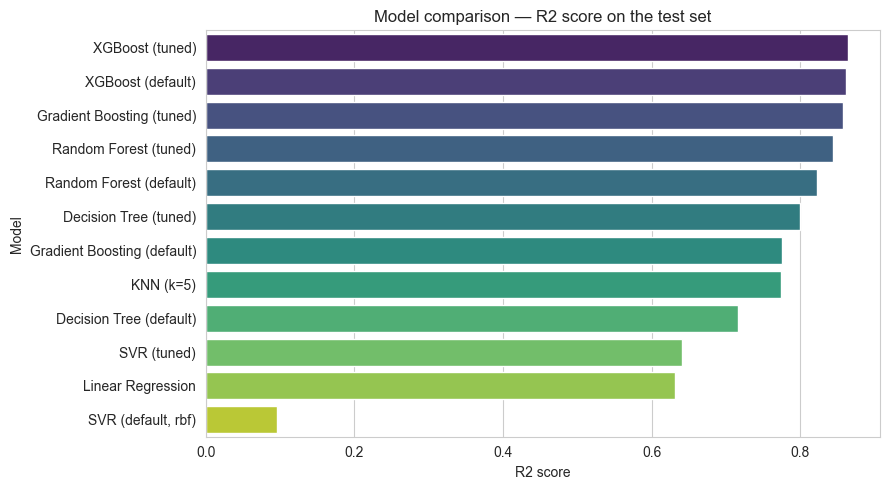

In [49]:
plt.figure(figsize=(9, 5))
sns.barplot(data=results_df, x="R2", y="Model", palette="viridis")
plt.title("Model comparison — R2 score on the test set")
plt.xlabel("R2 score")
plt.tight_layout()
plt.show()


**Summary of results**

The comparison table and chart above rank every model tried in this notebook by test-set R².
Tree-ensemble methods (Random Forest, Gradient Boosting, XGBoost — especially after tuning)
comfortably outperform Linear Regression and SVR, which struggle with the non-linear
relationship between flight duration/stops and price. KNN sits in between: it captures some
non-linearity but is held back by the curse of dimensionality introduced by one-hot encoding.

**Best model:** the tuned XGBoost/Gradient Boosting/Random Forest model with the highest R²
in the table above (see the top row of `results_df`) is selected as the final model and
persisted below.

**Potential next steps:**
- Engineer additional features such as "is weekend departure", or clustering rare `Airline`
  categories with very few flights.
- Try target-encoding for `Airline`/`Source`/`Destination` as an alternative to one-hot encoding,
  which could help Linear Regression/SVR.
- Use `RandomizedSearchCV` with a wider parameter space and more iterations for a more thorough
  tuning pass on the top 2–3 models, given more compute time/budget.
- Collect a full year of data to properly model seasonal effects on price.


In [50]:
best_model_name = results_df.iloc[0]["Model"]
model_lookup = {
    "Linear Regression": lin_reg,
    "KNN (k=5)": knn,
    "Decision Tree (default)": dt_default,
    "Decision Tree (tuned)": dt_grid.best_estimator_,
    "Random Forest (default)": rf_default,
    "Random Forest (tuned)": rf_grid.best_estimator_,
    "Gradient Boosting (default)": gb_default,
    "Gradient Boosting (tuned)": gb_grid.best_estimator_,
    "XGBoost (default)": xgb_default,
    "XGBoost (tuned)": xgb_grid.best_estimator_,
    "SVR (default, rbf)": svr_default,
    "SVR (tuned)": svr_grid.best_estimator_,
}
best_model = model_lookup[best_model_name]
print(f"Best model: {best_model_name}")


Best model: XGBoost (tuned)


In [51]:
import pickle

filename = "best_flight_fare_model.pkl"
with open(filename, "wb") as f:
    pickle.dump(best_model, f)

print(f"Model '{best_model_name}' saved successfully as {filename}")


Model 'XGBoost (tuned)' saved successfully as best_flight_fare_model.pkl
